# Notebook to create Figure 1

In [1]:
library(ggplot2)
library(dplyr)
library(stringr)
library(tidyr)
library(glue)
library(purrr)
library(ggtree)
library(ggtreeExtra)
library(readr)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


ggtree v3.10.1 For help: https://yulab-smu.top/treedata-book/

If you use the ggtree package suite in published research, please cite
the appropriate paper(s):

Guangchuang Yu, David Smith, Huachen Zhu, Yi Guan, Tommy Tsan-Yuk Lam.
ggtree: an R package for visualization and annotation of phylogenetic
trees with their covariates and other associated data. Methods in
Ecology and Evolution. 2017, 8(1):28-36. doi:10.1111/2041-210X.12628

G Yu. Data Integration, Manipulation and Visualization of Phylogenetic
Trees (1st ed.). Chapman and Hall/CRC. 2022. ISBN: 9781032233574

Guangchuang Yu. Using ggtree to visualize data on tree-like structures.
Current Protocols in Bioinformatics. 2020, 69:e96. doi:10.1002/cpbi.96



Attaching package: ‘ggtree’


The following object is masked from ‘package:tid

In [2]:
path <- glue("../../Data/Sequences/")

## 1. Species names modification

In [ ]:
# Taxa-names
## Starter for manual correction
data_set_content <- readr::read_csv(glue("{path}/bacteria_1_species_table.csv"), show_col_types = FALSE) |> 
  mutate(
    Bacteria = case_when(
      Bacteria == "Pseudomonas_sp._CVAP_3" ~ "Pseudomonas_sp._CVAP#3",
      Bacteria == "Clostridiales_genomosp._BVAB1" ~ "Candidatus_Lachnocurva_vaginae",
      TRUE ~ Bacteria
    ),
    Short_Name = Bacteria |> 
      str_replace("sp._.*", "sp.") |> 
      str_replace("Candidatus_", "Ca. ") |>
      str_remove("uncultured_") |>
      str_extract("[^_]*_[^_]*") |> 
      str_replace("_", " ") |> 
      
      str_remove("endosymbiont"),
    Short_Name = paste0("[", taxid, "] ", Short_Name),
    Genus = str_extract(Short_Name, "\\[[^\\]]+\\] (Ca\\. )?[^ ]+")
  )

In [ ]:
#load-plain-tree
tree_file <- glue("{path}/100_species.tree")
plain_tree <- treeio::read.newick(tree_file)
plain_tree
## Fix tip labels
plain_tree$tip.label <- plain_tree$tip.label |> 
 str_remove("__ex_Zhang_et_al._2022_|__nom._illeg._")


Phylogenetic tree with 100 tips and 200 internal nodes.

Tip labels:
  Mitsuokella_sp._AF21-1AC, uncultured_Pelosinus_sp., Veillonella_infantium, Eubacteriaceae_bacterium_UBA1433, Ruminococcaceae_bacterium_UBA1865, Candidatus_Gemmiger_avistercoris, ...
Node labels:
  , Bacteria, Bacillota, Negativicutes, Selenomonadales, Selenomonadaceae, ...

Rooted; no branch length.

## 2. Load the taxonomic tree

In [ ]:
# load-tree
tree <- tidytree::full_join(plain_tree, data_set_content, by = c("label" = "Bacteria"))
bacteria_id <- ape::Ntip(tree@phylo) + 2
tree <- tree |> 
    mutate(
        Phylum = node %in% tidytree::child(tree, bacteria_id), 
        label = if_else(Phylum, str_remove(label, "Candidatus_"), label),
        ## Aggregate phylum to classes of size at least 3
        Coarse_Phylum = label |> 
            forcats::fct_other(keep = c("Pseudomonadota", "Actinomycetota", "Bacillota", "Bacteroidota", "Cyanobacteriota", "Campylobacterota")) |> 
            forcats::fct_relevel("Pseudomonadota", "Actinomycetota", "Bacillota", "Bacteroidota", "Cyanobacteriota", "Campylobacterota")
    )
tree

'treedata' S4 object'.

...@ phylo:

Phylogenetic tree with 100 tips and 200 internal nodes.

Tip labels:
  Mitsuokella_sp._AF21-1AC, uncultured_Pelosinus_sp., Veillonella_infantium,
Eubacteriaceae_bacterium_UBA1433, Ruminococcaceae_bacterium_UBA1865,
Candidatus_Gemmiger_avistercoris, ...
Node labels:
  , Bacteria, Bacillota, Negativicutes, Selenomonadales, Selenomonadaceae, ...

Rooted; no branch length.

with the following features available:
  '', 'Set_1', 'No_set', 'taxid', 'Short_Name', 'Genus', 'Phylum',
'Coarse_Phylum'.

# The associated data tibble abstraction: 300 × 10
# The 'node', 'label' and 'isTip' are from the phylo tree.
    node label   isTip Set_1 No_set  taxid Short_Name Genus Phylum Coarse_Phylum
   <int> <chr>   <lgl> <lgl> <lgl>   <dbl> <chr>      <chr> <lgl>  <fct>        
 1     1 Mitsuo… TRUE  FALSE TRUE   2.29e6 [2292235]… [229… FALSE  Other        
 2     2 uncult… TRUE  FALSE TRUE   6.52e5 [652451] … [652… FALSE  Other        
 3     3 Veillo… TRUE  FALSE TRU

## 3. Generate Figure 1 

In [6]:
species_to_highlight <- c("[2587077] Rhizobium", "[2792044] Salinibacterium", "[2831468] Pseudaminobacter", "[1946184] Ca. Neomicrothrix", "[2079227] Arthrobacter", "[2782013] Streptomyces", "[3043615] Streptomyces")

In [ ]:
# base-plot
## base tree
p_base <- ggtree(tree, layout="circular", linewidth=0.2) + 
    geom_tiplab(data = td_filter(!No_set), aes(label = Genus), offset = 1, fontface = "italic") + 
    geom_tiplab(data = td_filter(No_set), aes(label = Genus), offset = 1, color = "grey70", fontface = "italic") + 
    geom_tiplab(data = td_filter(Genus %in% species_to_highlight), aes(label = Genus), offset = 1, color = "darkred", fontface = "italic") +
    paletteer::scale_color_paletteer_d("jcolors::pal5", guide = "none") +
    scale_alpha_discrete(range = c(0, 1), guide = "none") + 
    NULL

Warning message:
“`aes_()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`
ℹ The deprecated feature was likely used in the ggtree package.
  Please report the issue at <https://github.com/YuLab-SMU/ggtree/issues>.”
Warning message in fortify(data, ...):
“Arguments in `...` must be used.
✖ Problematic arguments:
• as.Date = as.Date
• yscale_mapping = yscale_mapping
• hang = hang
• linewidth = 0.2
ℹ Did you misspell an argument name?”
Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the ggtree package.
  Please report the issue at <https://github.com/YuLab-SMU/ggtree/issues>.”
Warning message:
“Using alpha for a discrete variable is not advised.”


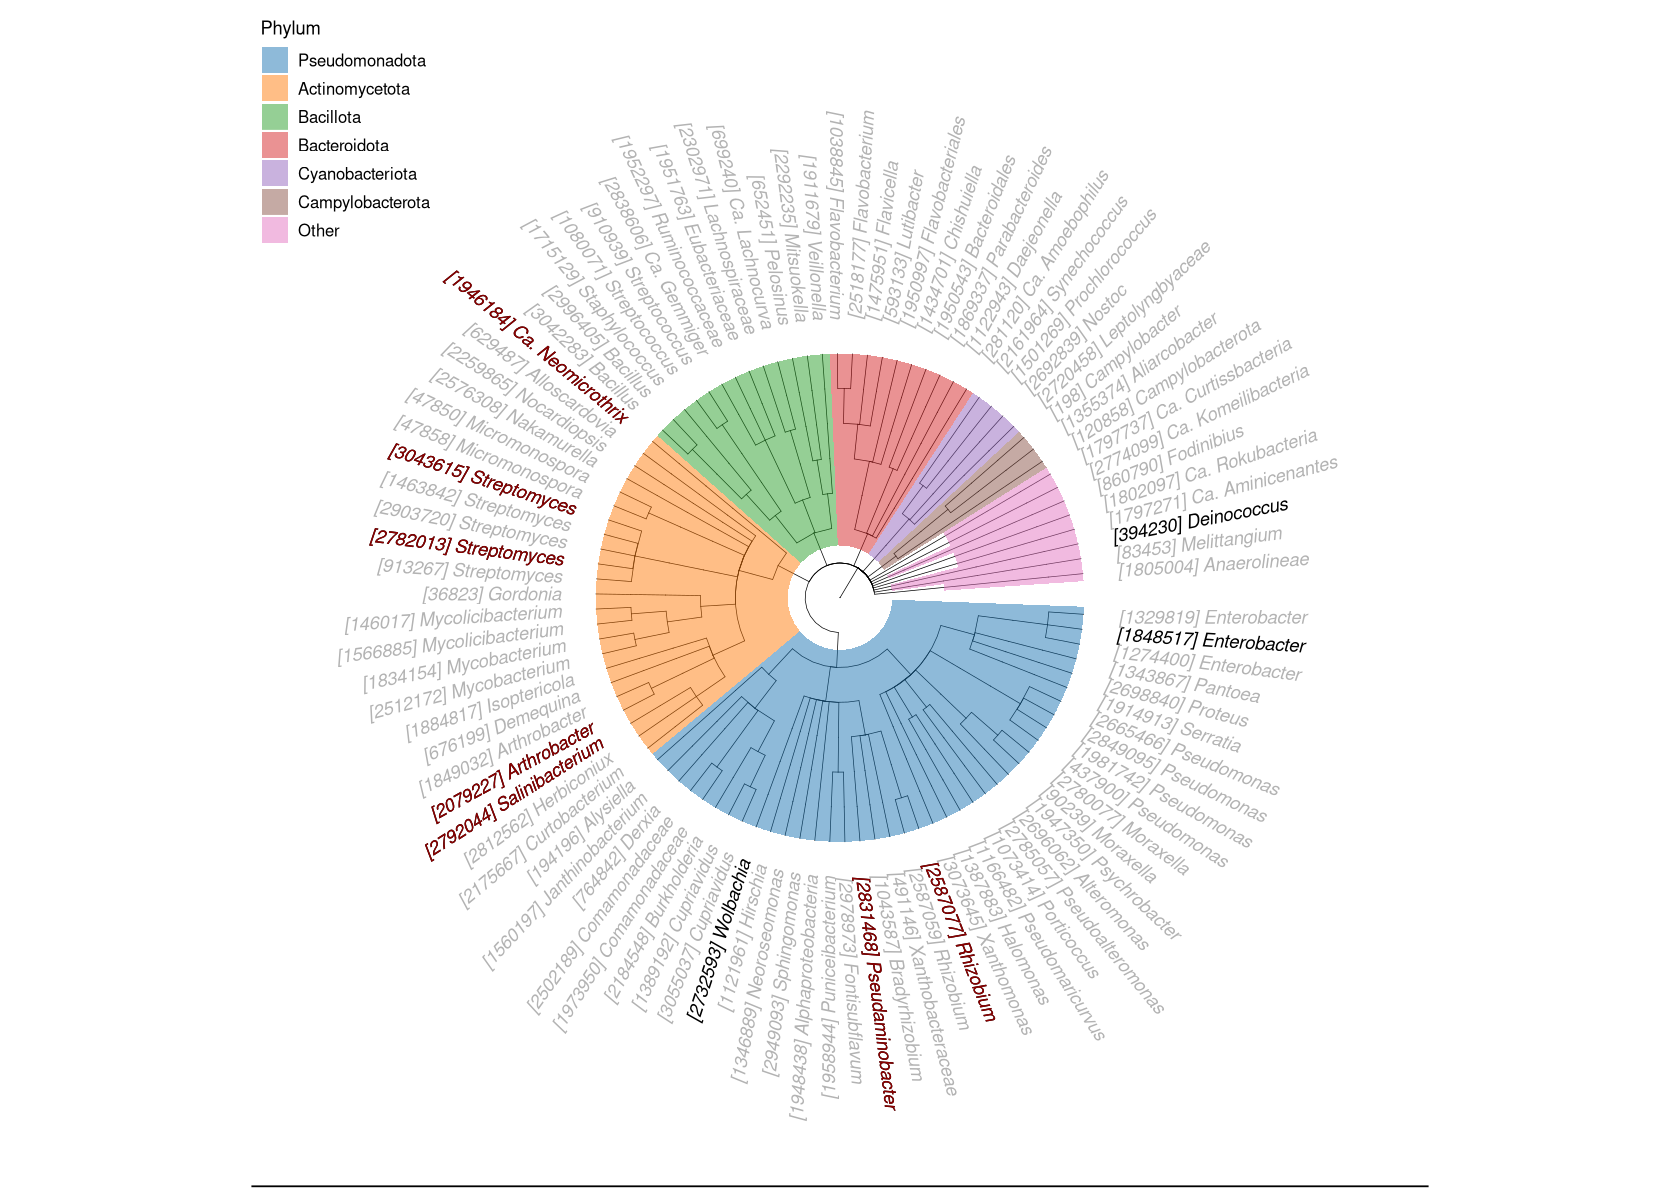

In [ ]:
#Tree with all taxa and most represented phylum
options(repr.plot.width = 14, repr.plot.height = 10)
(p <- p_base + 
    geom_hilight(td_filter(Phylum), mapping = aes(node = node, fill = Coarse_Phylum)) +
    paletteer::scale_fill_paletteer_d("ggsci::category20_d3", name = "Phylum", guide = guide_legend(ncol = 1)) + 
    theme_tree2(
        axis.text.x = element_blank(),
        legend.background = element_rect(fill = "transparent"),
        legend.position = c(0, 1), 
        legend.text = element_text(size = 10),
        legend.key.size = unit(6, "mm"),
        legend.justification = c(0, 1)
    ) +
    xlim(0, 13.5)
)

In [ ]:
# ggsave(glue("../../Results/taxonomic_tree_figure_1.png"), plot = p, 
#        width = 10, height = 10, units = "in", dpi = 300)